# Deepfake Detection: Dual-Stream RGB + Frequency Intelligence
### Official Dataset Only | PyTorch | EfficientNet-B0 + FFT | Robustness & Explainability

**Hackathon objective:** classify each official test image as REAL or FAKE and produce a reproducible `predictions.csv` containing all 3,000 test images.

This notebook is designed as a research workflow, not just a single classifier. It establishes a fair RGB baseline, tests a dual-stream RGB + frequency model, evaluates robustness under controlled image degradations, calibrates confidence, and produces interpretability outputs.

> **Important:** The official dataset's exact directory layout, label encoding, test-image naming convention, and `inferencetemplate.py` interface must be inspected before running the training and submission cells. Do not guess these details. The configuration cell below is the only place that should need dataset-specific edits.

## 1. Research idea and what makes this submission distinctive

A standard image classifier learns from visible RGB appearance. Our experimental model has two complementary streams:

1. **RGB stream — EfficientNet-B0:** learns facial texture, skin patterns, local inconsistencies, edges and visible artifacts.
2. **Frequency stream — FFT:** converts each image into a log-magnitude frequency representation. A lightweight CNN learns frequency-domain patterns that may complement RGB clues.
3. **Feature fusion:** concatenates both feature vectors and predicts the probability that an image is FAKE.

### Beyond training: our differentiating experiments

- **Ablation study:** compare RGB-only against RGB+FFT on the same split. This tests whether the frequency stream actually helps.
- **Robustness profile:** evaluate clean validation images and controlled JPEG compression, blur, noise, resizing and brightness changes.
- **Cross-condition consistency:** measure how much the fake probability changes when the same image is mildly degraded.
- **Confidence calibration:** use validation predictions to fit a temperature parameter, then compare calibration before and after.
- **Explainability:** generate Grad-CAM visualizations for the RGB stream and frequency maps for selected examples.
- **Efficiency report:** measure model size, parameter count, throughput and latency.

These experiments are defensible differentiators because they provide evidence about *why* the model works and where it fails. No technique can guarantee that nobody else will use it or that it will win. We will retain the dual-stream model only if validation results justify its added complexity.

### Experimental discipline

- Use only the official dataset for training and validation.
- Never use test labels (the test set is expected to be unlabeled).
- Keep one fixed, stratified validation split for fair comparisons.
- Do not select a model using test-set performance.
- Record random seeds and all important settings.

## 2. Runtime and reproducibility

Recommended runtime: Kaggle GPU or Google Colab GPU. The notebook can run on CPU for inspection, but training will be slow.

If pretrained ImageNet weights are used, they are initialization weights for the architecture, not an additional deepfake training dataset. Fine-tuning must use only the official hackathon training data.

**Before training:** check the competition rules and confirm that downloading the selected torchvision pretrained weights is permitted in the environment.

In [1]:
import os
import sys
import json
import math
import time
import random
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile, ImageEnhance, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.transforms import functional as TF
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve
)
from tqdm.auto import tqdm

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. Official dataset structure

The official package uses this exact layout:

```text
hackathon_dataset/
├── train/
│   ├── real/
│   └── fake/
├── test/
│   └── images/
├── train_metadata.csv
└── sample_submission.csv
```

Official labels: `real = 0`, `fake = 1`. The notebook reads `train_metadata.csv` and matches each `image_id` to the corresponding image in the class folders. Test images are read from `test/images/`. Do not change the official labels or use test images for training.


In [2]:
DATA_ROOT = Path("/kaggle/input/datasets/minahilyaqoob/hackathon-dataset/hackathon_dataset")

TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test" / "images"
TRAIN_METADATA = DATA_ROOT / "train_metadata.csv"

CLASS_TO_LABEL = {"real": 0, "fake": 1}

OUTPUT_DIR = Path("/kaggle/working/deepfake_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
VAL_SIZE = 0.20
SEED = 42
EPOCHS_RGB = 20
EPOCHS_FUSION = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_PRETRAINED = True
PIN_MEMORY = torch.cuda.is_available()

print("Train directory:", TRAIN_DIR)
print("Metadata:", TRAIN_METADATA)
print("Test directory:", TEST_DIR)
print("Output directory:", OUTPUT_DIR)
print("Device:", DEVICE)


Train directory: /kaggle/input/datasets/minahilyaqoob/hackathon-dataset/hackathon_dataset/train
Metadata: /kaggle/input/datasets/minahilyaqoob/hackathon-dataset/hackathon_dataset/train_metadata.csv
Test directory: /kaggle/input/datasets/minahilyaqoob/hackathon-dataset/hackathon_dataset/test/images
Output directory: /kaggle/working/deepfake_outputs
Device: cuda


## 4. Seed and dataset inspection

First inspect the actual files. This step checks class folders, image counts, formats, dimensions, and unreadable files. If the printed structure does not match the expected layout, stop and correct the configuration before proceeding.

In [3]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)

def show_tree(root, max_depth=3, max_items=12):
    root = Path(root)
    if not root.exists():
        print(f"Path does not exist: {root}")
        return
    for current, dirs, files in os.walk(root):
        rel = Path(current).relative_to(root)
        depth = len(rel.parts)
        if depth > max_depth:
            dirs[:] = []
            continue
        print("  " * depth + f"{Path(current).name}/")
        for filename in sorted(files)[:max_items]:
            print("  " * (depth + 1) + filename)
        if len(files) > max_items:
            print("  " * (depth + 1) + f"... and {len(files)-max_items} more files")

show_tree(DATA_ROOT)

hackathon_dataset/
  sample_submission.csv
  train_metadata.csv
  test/
    images/
      0020cba7-1d58-4784-91f9-6fc47d9f2806.jpg
      003fae32-30d9-441b-8fcf-073fc04bf1d1.jpg
      0061307d-aad7-4d74-a501-ba708c8b1ac8.jpg
      006aa5af-5db6-413b-a60f-fcc6071ddc3c.jpg
      009a6a38-29a4-46d4-8ecc-905d776d924e.jpg
      00a24788-f2c0-4ff0-8b14-35a259208179.jpg
      00b3e968-9f14-48e1-94af-bed1a153f582.jpg
      00bf115d-0b1b-4c9e-a8b5-b6f3d7e00218.jpg
      00f38e59-dd70-4655-b544-013a12363ed5.jpg
      014b3ea8-0ad0-4140-8b27-e861be7f4f04.jpg
      01526603-7f70-40c0-a5e3-08df6a0dde8e.jpg
      0158ce3d-4da9-4010-8b6b-7c52dda249b9.jpg
      ... and 2988 more files
  train/
    fake/
      000f994a-4322-40c0-bb30-0830830cd077.jpg
      001cdd79-9865-4c3e-b521-b5e235d93a52.jpg
      0037fa20-9f97-44c2-9343-fe38322ffd8b.jpg
      004d031f-effc-4a75-aed5-cd7c90b2c51a.jpg
      0055a212-3aee-4d19-b776-bff18f2d00ec.jpg
      00c2c8ce-770f-4d96-a9f4-61df2821da2d.jpg
      00cffdd4-f7f4-4

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_images(folder):
    folder = Path(folder)
    if not folder.exists():
        return []
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

# Build an image lookup from the official class folders.
image_lookup = {}
for class_name in CLASS_TO_LABEL:
    class_folder = TRAIN_DIR / class_name
    for image_path in list_images(class_folder):
        if image_path.stem in image_lookup:
            raise ValueError(f"Duplicate training image ID: {image_path.stem}")
        image_lookup[image_path.stem] = image_path

if not TRAIN_METADATA.exists():
    raise FileNotFoundError(f"Missing official metadata file: {TRAIN_METADATA}")

train_metadata = pd.read_csv(TRAIN_METADATA)
if not {"image_id", "label"}.issubset(train_metadata.columns):
    raise ValueError("train_metadata.csv must contain image_id and label columns.")

train_metadata["image_id"] = train_metadata["image_id"].astype(str)
train_metadata["label"] = pd.to_numeric(train_metadata["label"], errors="raise").astype(int)

if not set(train_metadata["label"].unique()).issubset({0, 1}):
    raise ValueError("Official labels must be 0 (REAL) or 1 (FAKE).")
if train_metadata["image_id"].duplicated().any():
    raise ValueError("Duplicate image_id values found in train_metadata.csv.")

missing_ids = sorted(set(train_metadata["image_id"]) - set(image_lookup))
if missing_ids:
    raise FileNotFoundError(
        f"{len(missing_ids)} metadata image IDs have no matching image. "
        f"Examples: {missing_ids[:5]}"
    )

train_files = [image_lookup[image_id] for image_id in train_metadata["image_id"]]
train_labels = train_metadata["label"].tolist()

# Verify metadata labels agree with their official class folders.
for image_id, image_path, label in zip(train_metadata["image_id"], train_files, train_labels):
    folder_label = CLASS_TO_LABEL[image_path.parent.name.lower()]
    if folder_label != label:
        raise ValueError(f"Label mismatch for {image_id}: metadata={label}, folder={folder_label}")

test_files = list_images(TEST_DIR)

print("Training images matched to metadata:", len(train_files))
print("Training label counts:", Counter(train_labels))
print("Test images:", len(test_files))
print("Test folder:", TEST_DIR)

if len(train_files) == 0:
    raise RuntimeError("No training images found. Correct DATA_ROOT.")
if len(test_files) == 0:
    raise RuntimeError("No test images found. Correct TEST_DIR.")


Training images matched to metadata: 7000
Training label counts: Counter({1: 3522, 0: 3478})
Test images: 3000
Test folder: /kaggle/input/datasets/minahilyaqoob/hackathon-dataset/hackathon_dataset/test/images


In [5]:
# Inspect image formats, dimensions and corrupted files.
format_counts = Counter()
dimension_counts = Counter()
bad_files = []

for path in tqdm(train_files + test_files, desc="Inspecting images"):
    try:
        with Image.open(path) as img:
            format_counts[img.format] += 1
            dimension_counts[img.size] += 1
            img.verify()
    except Exception as exc:
        bad_files.append((str(path), str(exc)))

print("Formats:", format_counts)
print("Most common dimensions:", dimension_counts.most_common(10))
print("Unreadable/corrupted images:", len(bad_files))
if bad_files[:10]:
    display(pd.DataFrame(bad_files[:10], columns=["path", "error"]))

Inspecting images:   0%|          | 0/10000 [00:00<?, ?it/s]

Formats: Counter({'JPEG': 10000})
Most common dimensions: [((224, 224), 10000)]
Unreadable/corrupted images: 0


## 5. Visual exploration

Review random examples from both classes. This is a sanity check for labels, face crops, image quality and possible dataset artifacts. Do not infer that a model is good simply because a few examples look easy.

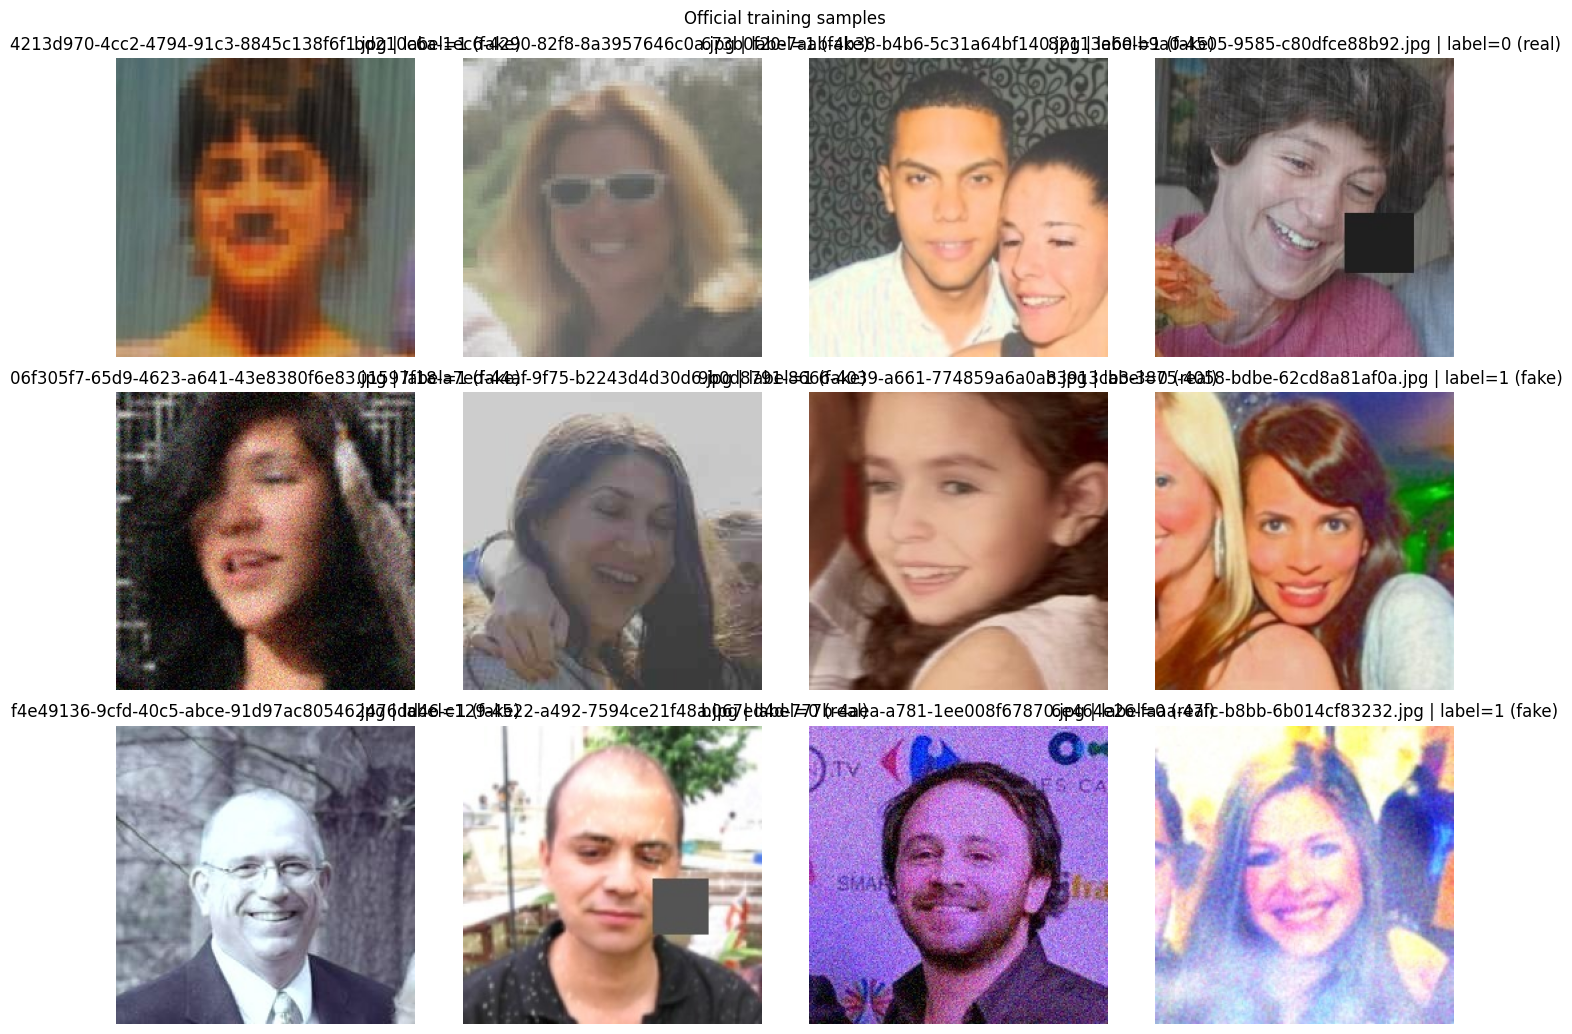

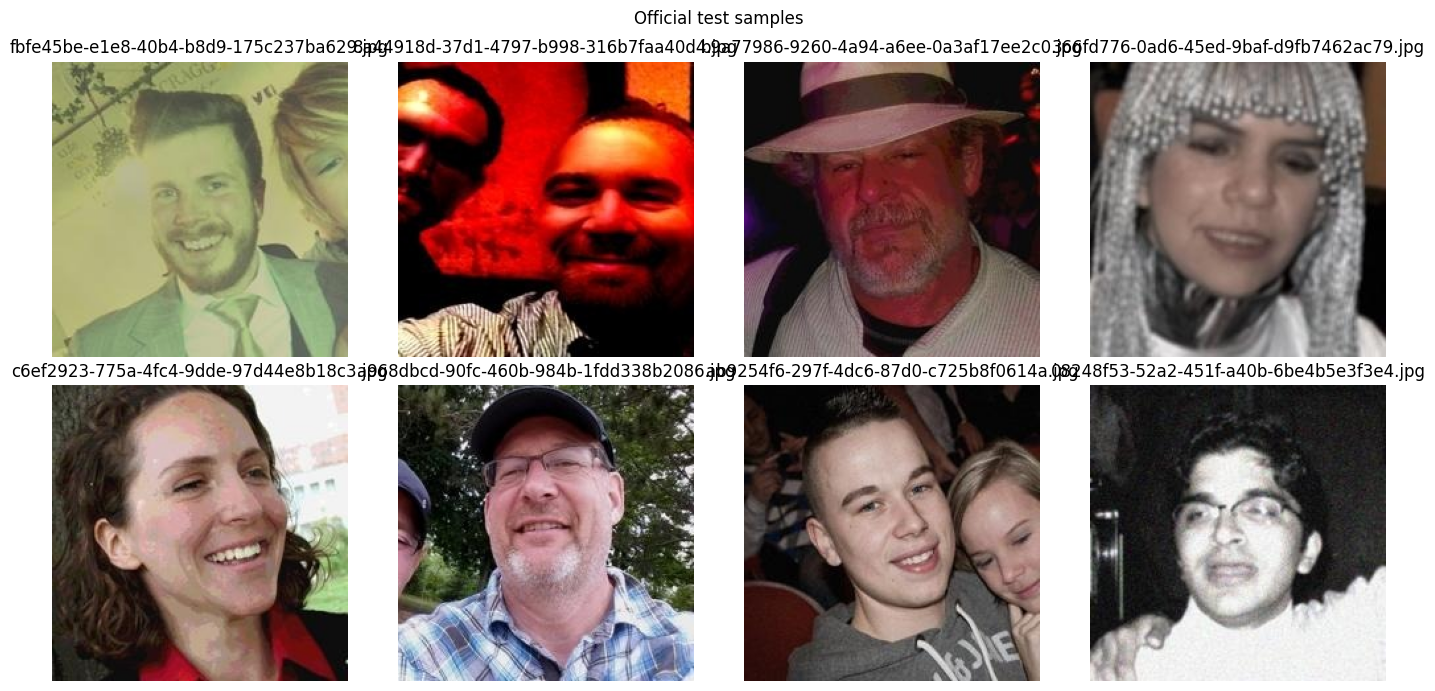

In [8]:
def plot_samples(files, labels=None, class_names=None, n=8, title="Sample images"):
    if len(files) == 0:
        print("No files to display.")
        return
    indices = np.random.choice(len(files), size=min(n, len(files)), replace=False)
    cols = 4
    rows = math.ceil(len(indices) / cols)
    plt.figure(figsize=(14, 3.5 * rows))
    for plot_i, idx in enumerate(indices, 1):
        img = Image.open(files[idx]).convert("RGB")
        plt.subplot(rows, cols, plot_i)
        plt.imshow(img)
        label_text = ""
        if labels is not None:
            label_text = f" | label={labels[idx]}"
            if class_names:
                label_text += f" ({class_names.get(labels[idx], 'unknown')})"
        plt.title(Path(files[idx]).name + label_text)
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

label_names = {v: k for k, v in CLASS_TO_LABEL.items()}
plot_samples(train_files, train_labels, label_names, n=12, title="Official training samples")
plot_samples(test_files, n=8, title="Official test samples")

## 6. Fixed stratified train/validation split

If the organizers provide a separate official validation split, use that instead and adapt this section. Otherwise, create a stratified split from the official training data. This split is reused for every experiment so comparisons remain fair.

In [9]:
indices = np.arange(len(train_files))
train_idx, val_idx = train_test_split(
    indices,
    test_size=VAL_SIZE,
    random_state=SEED,
    stratify=np.asarray(train_labels)
)

print("Train split:", len(train_idx))
print("Validation split:", len(val_idx))
print("Train distribution:", Counter(np.asarray(train_labels)[train_idx]))
print("Validation distribution:", Counter(np.asarray(train_labels)[val_idx]))

Train split: 5600
Validation split: 1400
Train distribution: Counter({np.int64(1): 2818, np.int64(0): 2782})
Validation distribution: Counter({np.int64(1): 704, np.int64(0): 696})


## 7. Preprocessing and augmentation

The RGB branch receives ImageNet-normalized RGB images. The FFT branch is computed from the same resized image before normalization, using grayscale log-magnitude FFT.

Augmentations are deliberately moderate. Aggressive blur, random erasing or heavy geometric distortion could remove useful manipulation clues. The paired training pipeline includes mild JPEG compression and low-level noise with limited probability. Their strength should be tuned using validation results.

In [10]:
from torchvision.transforms import InterpolationMode

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.08, hue=0.02)
    ], p=0.35),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

## 8. Dataset class with paired RGB and FFT inputs

For each image:
- `rgb`: resized, normalized 3-channel image.
- `fft`: single-channel log-magnitude frequency map.
- `label`: 0 for REAL, 1 for FAKE.

The FFT is computed after resizing and before ImageNet normalization. We use `fftshift` so low frequencies appear near the center. The log transform compresses the dynamic range.

In [11]:
def make_frequency_map(rgb_tensor):
    # rgb_tensor is [3, H, W] in [0, 1], before ImageNet normalization.
    gray = 0.299 * rgb_tensor[0] + 0.587 * rgb_tensor[1] + 0.114 * rgb_tensor[2]
    spectrum = torch.fft.fft2(gray, norm="ortho")
    spectrum = torch.fft.fftshift(spectrum)
    magnitude = torch.abs(spectrum)
    log_magnitude = torch.log1p(magnitude)
    # Per-image normalization stabilizes the input scale.
    log_magnitude = (log_magnitude - log_magnitude.mean()) / (log_magnitude.std() + 1e-6)
    return log_magnitude.unsqueeze(0).float()

class DeepfakeDataset(Dataset):
    def __init__(self, files, labels=None, transform=None, return_path=False):
        self.files = list(files)
        self.labels = None if labels is None else list(labels)
        self.transform = transform
        self.return_path = return_path

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path = self.files[index]
        image = Image.open(path).convert("RGB")
        if self.transform is None:
            rgb_raw = TF.to_tensor(image.resize((IMAGE_SIZE, IMAGE_SIZE)))
        else:
            resized = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(image)
            rgb_raw = TF.to_tensor(resized)
            rgb_aug = self.transform(image)
            rgb_input = rgb_aug
        if self.transform is None:
            rgb_input = (rgb_raw - torch.tensor(IMAGENET_MEAN)[:, None, None]) / torch.tensor(IMAGENET_STD)[:, None, None]
        fft_input = make_frequency_map(rgb_raw)
        if self.labels is None:
            result = (rgb_input, fft_input)
        else:
            result = (rgb_input, fft_input, torch.tensor(self.labels[index], dtype=torch.long))
        if self.return_path:
            return (*result, str(path))
        return result

### Important alignment note

The starter dataset class above computes FFT from the resized source image while RGB training augmentation may apply random flips/rotations. For a rigorous paired dual-stream experiment, both branches must receive the **same geometric transform**. The next cell supplies a paired dataset implementation that applies shared flips and rotations before deriving both views. Use this paired dataset for the dual-stream experiment.

In [12]:
class PairedDeepfakeDataset(Dataset):
    def __init__(self, files, labels=None, training=False, return_path=False):
        self.files = list(files)
        self.labels = None if labels is None else list(labels)
        self.training = training
        self.return_path = return_path
        self.resize = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=InterpolationMode.BILINEAR)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        path = self.files[index]
        image = Image.open(path).convert("RGB")
        image = self.resize(image)

        if self.training:
            if random.random() < 0.5:
                image = TF.hflip(image)
            angle = random.uniform(-5, 5)
            image = TF.rotate(image, angle, interpolation=InterpolationMode.BILINEAR)
            if random.random() < 0.35:
                image = ImageEnhance.Brightness(image).enhance(random.uniform(0.88, 1.12))
                image = ImageEnhance.Contrast(image).enhance(random.uniform(0.88, 1.12))
            if random.random() < 0.25:
                import io
                buffer = io.BytesIO()
                image.save(buffer, format="JPEG", quality=random.randint(55, 90))
                buffer.seek(0)
                image = Image.open(buffer).convert("RGB")

        rgb_raw = TF.to_tensor(image)
        if self.training and random.random() < 0.15:
            rgb_raw = (rgb_raw + torch.randn_like(rgb_raw) * 0.012).clamp(0, 1)
        fft_input = make_frequency_map(rgb_raw)
        rgb_input = TF.normalize(rgb_raw, IMAGENET_MEAN, IMAGENET_STD)

        if self.labels is None:
            result = (rgb_input, fft_input)
        else:
            result = (rgb_input, fft_input, torch.tensor(self.labels[index], dtype=torch.long))

        if self.return_path:
            return (*result, str(path))
        return result

train_labels_array = np.asarray(train_labels)
train_files_split = [train_files[i] for i in train_idx]
train_labels_split = train_labels_array[train_idx].tolist()
val_files_split = [train_files[i] for i in val_idx]
val_labels_split = train_labels_array[val_idx].tolist()

train_dataset = PairedDeepfakeDataset(train_files_split, train_labels_split, training=True)
val_dataset = PairedDeepfakeDataset(val_files_split, val_labels_split, training=False)
test_dataset = PairedDeepfakeDataset(test_files, labels=None, training=False, return_path=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

rgb_batch, fft_batch, label_batch = next(iter(train_loader))
print("RGB batch:", rgb_batch.shape)
print("FFT batch:", fft_batch.shape)
print("Label batch:", label_batch.shape)

RGB batch: torch.Size([32, 3, 224, 224])
FFT batch: torch.Size([32, 1, 224, 224])
Label batch: torch.Size([32])


## 9. Model A — RGB-only EfficientNet-B0 baseline

This is our control experiment. We first train a conventional RGB model. The dual-stream model must be compared against this baseline using the same split and evaluation metrics.

In [13]:
def build_rgb_model(pretrained=True):
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 2)
    return model

rgb_model = build_rgb_model(pretrained=USE_PRETRAINED).to(DEVICE)
print(rgb_model.classifier)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 181MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


## 10. Model B — RGB + FFT dual-stream fusion

The RGB stream uses EfficientNet-B0. The frequency stream is a compact CNN that processes the 1-channel FFT map. Their feature vectors are concatenated, passed through a fusion head, and classified into REAL/FAKE logits.

This is an experimental design. The validation ablation determines whether it is worth keeping.

In [14]:
class FrequencyBranch(nn.Module):
    def __init__(self, output_dim=128):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.SiLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.SiLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.SiLU(inplace=True),
            nn.Conv2d(128, 192, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(192), nn.SiLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )
        self.projection = nn.Sequential(
            nn.Linear(192, output_dim),
            nn.BatchNorm1d(output_dim),
            nn.SiLU(inplace=True),
            nn.Dropout(0.25)
        )

    def forward(self, x):
        return self.projection(self.features(x))

class RGBFrequencyFusion(nn.Module):
    def __init__(self, pretrained=True, frequency_dim=128):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
        backbone = models.efficientnet_b0(weights=weights)
        self.rgb_features = backbone.features
        self.rgb_pool = backbone.avgpool
        rgb_dim = backbone.classifier[1].in_features
        self.frequency_branch = FrequencyBranch(output_dim=frequency_dim)
        self.classifier = nn.Sequential(
            nn.Linear(rgb_dim + frequency_dim, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(256, 2)
        )

    def forward(self, rgb, fft):
        rgb_features = self.rgb_pool(self.rgb_features(rgb)).flatten(1)
        fft_features = self.frequency_branch(fft)
        fused = torch.cat([rgb_features, fft_features], dim=1)
        return self.classifier(fused)

fusion_model = RGBFrequencyFusion(pretrained=USE_PRETRAINED).to(DEVICE)
print("Dual-stream model initialized.")

Dual-stream model initialized.


## 11. Training utilities

We use cross-entropy loss, AdamW, a validation-based scheduler, early stopping and mixed precision when CUDA is available. The best checkpoint is selected using validation ROC-AUC when both classes are present; otherwise validation loss is used.

The model outputs two logits: index 0 = REAL and index 1 = FAKE.

In [15]:
from torch.cuda.amp import autocast, GradScaler

def compute_metrics(y_true, probabilities):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)
    y_pred = (probabilities >= 0.5).astype(int)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_fake": precision_score(y_true, y_pred, zero_division=0),
        "recall_fake": recall_score(y_true, y_pred, zero_division=0),
        "f1_fake": f1_score(y_true, y_pred, zero_division=0),
    }
    if len(np.unique(y_true)) == 2:
        metrics["roc_auc"] = roc_auc_score(y_true, probabilities)
    else:
        metrics["roc_auc"] = float("nan")
    return metrics

def run_epoch(model, loader, optimizer=None, dual_stream=False, scaler=None):
    training = optimizer is not None
    model.train(training)
    criterion = nn.CrossEntropyLoss()
    losses, all_labels, all_probs = [], [], []

    for batch in tqdm(loader, leave=False):
        rgb, fft, labels = batch[:3]
        rgb = rgb.to(DEVICE, non_blocking=True)
        fft = fft.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast(enabled=(DEVICE.type == "cuda")):
                logits = model(rgb, fft) if dual_stream else model(rgb)
                loss = criterion(logits, labels)

            if training:
                if scaler is not None and DEVICE.type == "cuda":
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()

        probs = torch.softmax(logits.detach(), dim=1)[:, 1]
        losses.append(loss.item())
        all_labels.extend(labels.detach().cpu().numpy().tolist())
        all_probs.extend(probs.cpu().numpy().tolist())

    metrics = compute_metrics(all_labels, all_probs)
    metrics["loss"] = float(np.mean(losses))
    return metrics, np.asarray(all_labels), np.asarray(all_probs)

def train_model(model, train_loader, val_loader, epochs, save_path, dual_stream=False):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=2
    )
    scaler = GradScaler(enabled=(DEVICE.type == "cuda"))
    best_score = -np.inf
    best_loss = np.inf
    patience_counter = 0
    history = []

    for epoch in range(1, epochs + 1):
        train_metrics, _, _ = run_epoch(
            model, train_loader, optimizer=optimizer, dual_stream=dual_stream, scaler=scaler
        )
        val_metrics, _, _ = run_epoch(
            model, val_loader, optimizer=None, dual_stream=dual_stream
        )

        score = val_metrics["roc_auc"]
        if np.isnan(score):
            score = -val_metrics["loss"]
        scheduler.step(score)

        row = {"epoch": epoch, **{f"train_{k}": v for k, v in train_metrics.items()},
               **{f"val_{k}": v for k, v in val_metrics.items()},
               "learning_rate": optimizer.param_groups[0]["lr"]}
        history.append(row)
        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val acc {val_metrics['accuracy']:.4f} | "
            f"val AUC {val_metrics['roc_auc']:.4f}"
        )

        improved = score > best_score or (np.isnan(score) and val_metrics["loss"] < best_loss)
        if improved:
            best_score = score
            best_loss = val_metrics["loss"]
            torch.save(model.state_dict(), save_path)
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print("Early stopping.")
                break

    return pd.DataFrame(history)

## 12. Experiment 1 — train the RGB baseline

Train the baseline first. If compute time is limited, reduce `EPOCHS_RGB` for a smoke test, then run the full experiment.

In [17]:
rgb_checkpoint = OUTPUT_DIR / "efficientnet_b0_rgb_best.pth"

rgb_history = train_model(
    rgb_model, train_loader, val_loader,
    epochs=EPOCHS_RGB,
    save_path=rgb_checkpoint,
    dual_stream=False
)

display(rgb_history)
rgb_history.to_csv(OUTPUT_DIR / "rgb_training_history.csv", index=False)

rgb_model.load_state_dict(torch.load(rgb_checkpoint, map_location=DEVICE))

/tmp/ipykernel_50/3481574877.py:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(DEVICE.type == "cuda"))


  0%|          | 0/175 [00:00<?, ?it/s]

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2a742282c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a2a742282c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloade

  0%|          | 0/44 [00:00<?, ?it/s]

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):


Epoch 01/20 | train loss 0.1460 | val loss 0.6453 | val acc 0.8071 | val AUC 0.8708


... (23 outputs left out)

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):


Epoch 06/20 | train loss 0.0565 | val loss 0.8572 | val acc 0.8136 | val AUC 0.8691
Early stopping.


,epoch,train_accuracy,train_precision_fake,train_recall_fake,train_f1_fake,train_roc_auc,train_loss,val_accuracy,val_precision_fake,val_recall_fake,val_f1_fake,val_roc_auc,val_loss,learning_rate
0,1,0.941964,0.938754,0.946416,0.942569,0.986867,0.146040,0.807143,0.819118,0.791193,0.804913,0.870846,0.645338,0.00010
1,2,0.955536,0.953406,0.958481,0.955937,0.992389,0.114095,0.822857,0.838279,0.802557,0.820029,0.876327,0.741884,0.00010
2,3,0.961429,0.961021,0.962385,0.961702,0.993601,0.100996,0.815714,0.823188,0.806818,0.814921,0.871799,0.736736,0.00010
3,4,0.962143,0.961402,0.963449,0.962425,0.994652,0.094246,0.819286,0.826339,0.811080,0.818638,0.873628,0.817727,0.00010
4,5,0.970000,0.968529,0.971966,0.970244,0.996106,0.079346,0.815000,0.835596,0.786932,0.810534,0.872857,0.842276,0.00005
5,6,0.981071,0.980510,0.981902,0.981206,0.998034,0.056470,0.813571,0.823358,0.801136,0.812095,0.869129,0.857242,0.00005


<All keys matched successfully>

## 13. Experiment 2 — train the RGB + FFT fusion model

The dual-stream model uses the same data split. Save the best validation checkpoint.

In [18]:
fusion_checkpoint = OUTPUT_DIR / "rgb_fft_fusion_best.pth"

fusion_history = train_model(
    fusion_model, train_loader, val_loader,
    epochs=EPOCHS_FUSION,
    save_path=fusion_checkpoint,
    dual_stream=True
)

display(fusion_history)
fusion_history.to_csv(OUTPUT_DIR / "fusion_training_history.csv", index=False)

fusion_model.load_state_dict(torch.load(fusion_checkpoint, map_location=DEVICE))

/tmp/ipykernel_50/3481574877.py:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=(DEVICE.type == "cuda"))


  0%|          | 0/175 [00:00<?, ?it/s]

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):


  0%|          | 0/44 [00:00<?, ?it/s]

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):


Epoch 01/20 | train loss 0.5823 | val loss 0.5075 | val acc 0.7543 | val AUC 0.8346


... (68 outputs left out)

/tmp/ipykernel_50/3481574877.py:35: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=(DEVICE.type == "cuda")):


Epoch 15/20 | train loss 0.0508 | val loss 0.7092 | val acc 0.8136 | val AUC 0.8746
Early stopping.


,epoch,train_accuracy,train_precision_fake,train_recall_fake,train_f1_fake,train_roc_auc,train_loss,val_accuracy,val_precision_fake,val_recall_fake,val_f1_fake,val_roc_auc,val_loss,learning_rate
0,1,0.696607,0.695288,0.706884,0.701038,0.765206,0.582279,0.754286,0.757880,0.751420,0.754636,0.834591,0.507516,0.000100
1,2,0.804643,0.801399,0.813343,0.807327,0.874024,0.447703,0.800000,0.795265,0.811080,0.803094,0.859281,0.473655,0.000100
2,3,0.844286,0.845035,0.845635,0.845335,0.915988,0.370270,0.807857,0.804196,0.816761,0.810430,0.872122,0.459214,0.000100
3,4,0.878036,0.875484,0.883251,0.879350,0.942916,0.305296,0.800714,0.811127,0.786932,0.798846,0.871088,0.488649,0.000100
4,5,0.900536,0.897923,0.905252,0.901573,0.962804,0.248539,0.803571,0.814056,0.789773,0.801730,0.870922,0.509795,0.000100
5,6,0.921071,0.922776,0.920156,0.921464,0.977795,0.194254,0.811429,0.821637,0.798295,0.809798,0.864476,0.550084,0.000050
6,7,0.947500,0.949110,0.946416,0.947761,0.988085,0.144473,0.814286,0.825513,0.799716,0.812410,0.873848,0.562786,0.000050
7,8,0.956964,0.960343,0.953868,0.957095,0.991069,0.125945,0.806429,0.806223,0.809659,0.807938,0.870395,0.588074,0.000050
8,9,0.963036,0.962779,0.963804,0.963291,0.993567,0.106895,0.805000,0.809182,0.801136,0.805139,0.867750,0.596637,0.000050
9,10,0.968571,0.968772,0.968772,0.968772,0.995613,0.090426,0.813571,0.808067,0.825284,0.816585,0.874710,0.621996,0.000050


<All keys matched successfully>

## 14. Fair validation comparison and diagnostic report

Compare both models on exactly the same validation examples. The model with the better headline metric is not automatically the winner: also consider robustness, calibration and inference cost.

  0%|          | 0/44 [00:00<?, ?it/s]

  0%|          | 0/44 [00:00<?, ?it/s]

,model,accuracy,precision_fake,recall_fake,f1_fake,roc_auc
0,EfficientNet-B0 RGB,0.825000,0.84000,0.805398,0.822335,0.876050
1,EfficientNet-B0 + FFT fusion,0.812143,0.83871,0.775568,0.805904,0.875319


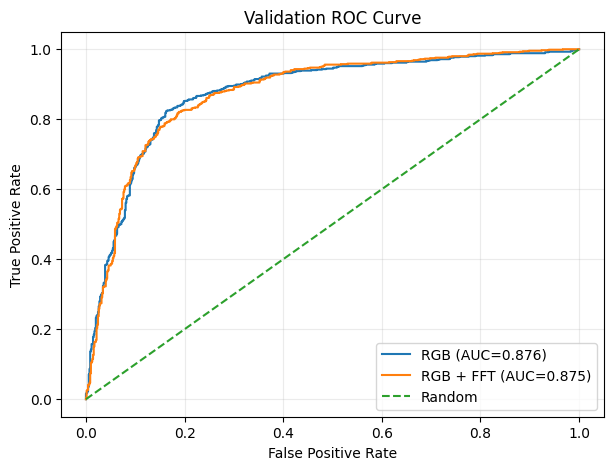

In [19]:
@torch.no_grad()
def predict_validation(model, loader, dual_stream=False):
    model.eval()
    labels_all, probs_all = [], []
    for rgb, fft, labels in tqdm(loader, leave=False):
        rgb = rgb.to(DEVICE)
        fft = fft.to(DEVICE)
        logits = model(rgb, fft) if dual_stream else model(rgb)
        probs = torch.softmax(logits, dim=1)[:, 1]
        labels_all.extend(labels.numpy().tolist())
        probs_all.extend(probs.cpu().numpy().tolist())
    return np.asarray(labels_all), np.asarray(probs_all)

y_val, p_rgb = predict_validation(rgb_model, val_loader, dual_stream=False)
_, p_fusion = predict_validation(fusion_model, val_loader, dual_stream=True)

comparison = pd.DataFrame([
    {"model": "EfficientNet-B0 RGB", **compute_metrics(y_val, p_rgb)},
    {"model": "EfficientNet-B0 + FFT fusion", **compute_metrics(y_val, p_fusion)}
])
display(comparison)
comparison.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

plt.figure(figsize=(7, 5))
for name, probs in [("RGB", p_rgb), ("RGB + FFT", p_fusion)]:
    if len(np.unique(y_val)) == 2:
        fpr, tpr, _ = roc_curve(y_val, probs)
        auc_value = roc_auc_score(y_val, probs)
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 15. Error analysis — where does the model fail?

Inspect false positives and false negatives. This often reveals more useful information than looking only at overall accuracy.

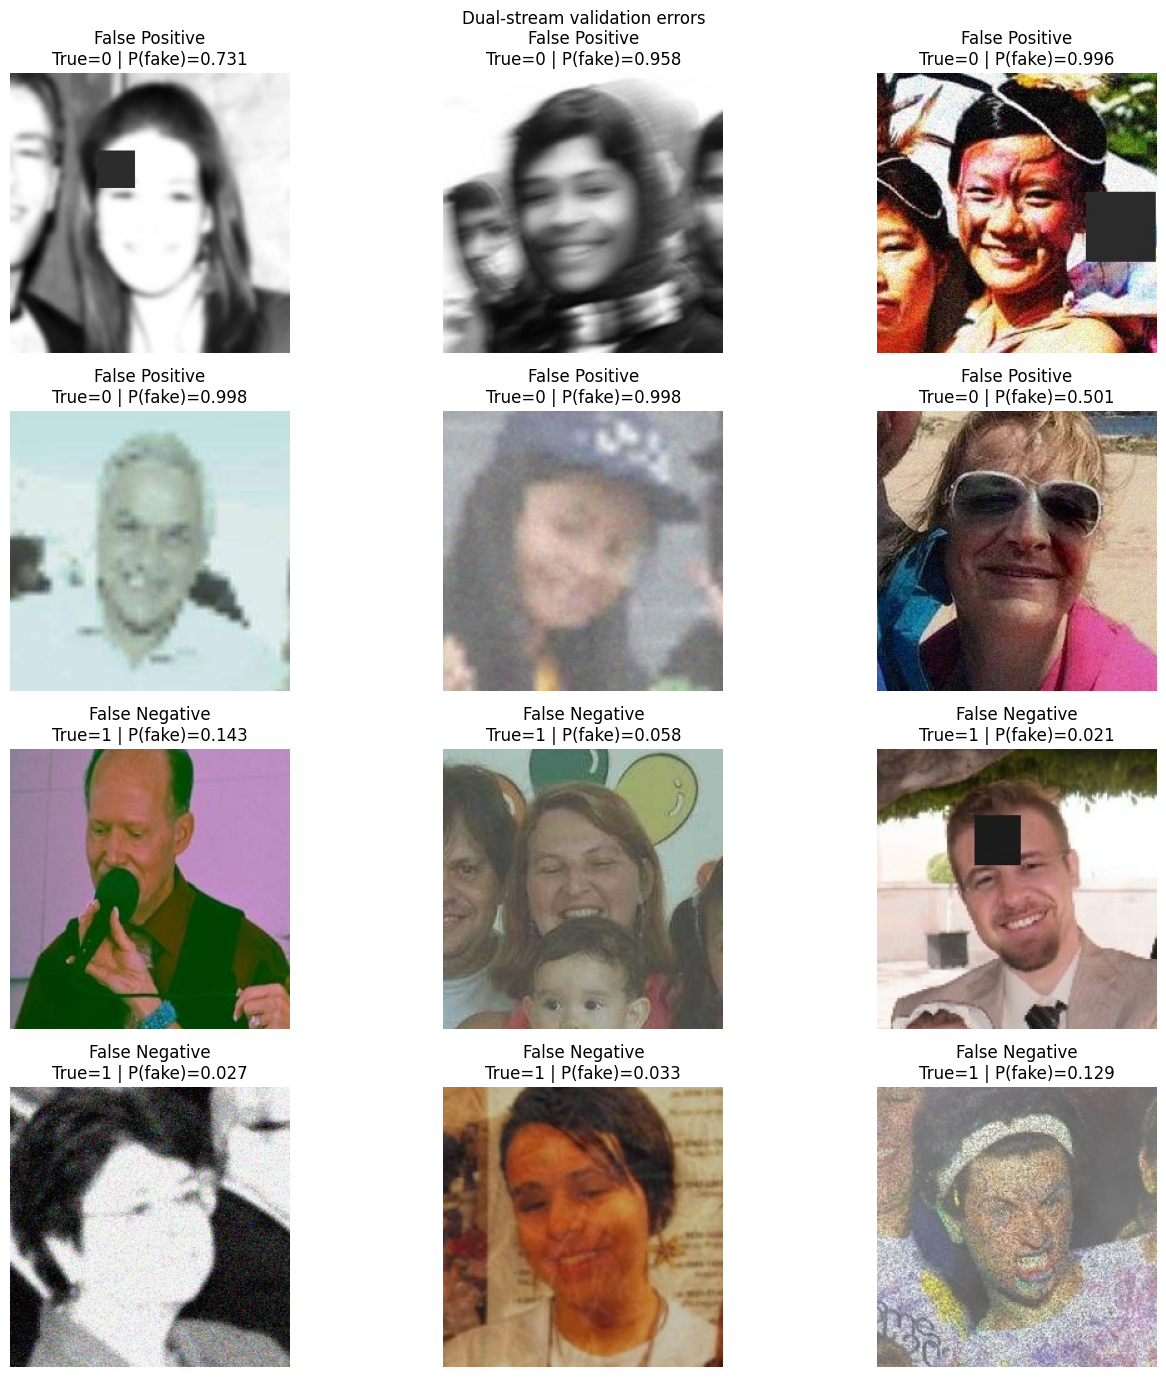

In [20]:
def show_error_cases(files, y_true, probs, title, max_each=6):
    preds = (probs >= 0.5).astype(int)
    fp = np.where((y_true == 0) & (preds == 1))[0][:max_each]
    fn = np.where((y_true == 1) & (preds == 0))[0][:max_each]
    selected = [(i, "False Positive") for i in fp] + [(i, "False Negative") for i in fn]
    if not selected:
        print("No errors at threshold 0.5.")
        return
    plt.figure(figsize=(14, 3.5 * math.ceil(len(selected) / 3)))
    for j, (idx, kind) in enumerate(selected, 1):
        image = Image.open(files[idx]).convert("RGB")
        plt.subplot(math.ceil(len(selected) / 3), 3, j)
        plt.imshow(image)
        plt.title(f"{kind}\nTrue={y_true[idx]} | P(fake)={probs[idx]:.3f}")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_error_cases(val_files_split, y_val, p_fusion, "Dual-stream validation errors")

## 16. Robustness evaluation — controlled image degradations

This is one of the main differentiating experiments. We test the same validation images under controlled transformations and measure:
- Accuracy and ROC-AUC under each condition.
- Mean absolute change in fake probability relative to the clean image.
- Whether model predictions flip after mild degradation.

These are validation diagnostics, not extra training data. The transformed images are generated from the official validation images only.

In [21]:
def apply_degradation(image, condition):
    if condition == "clean":
        return image
    if condition == "jpeg_quality_60":
        import io
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=60)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")
    if condition == "jpeg_quality_35":
        import io
        buffer = io.BytesIO()
        image.save(buffer, format="JPEG", quality=35)
        buffer.seek(0)
        return Image.open(buffer).convert("RGB")
    if condition == "mild_blur":
        return image.filter(ImageFilter.GaussianBlur(radius=0.7))
    if condition == "brightness_down":
        return ImageEnhance.Brightness(image).enhance(0.8)
    if condition == "brightness_up":
        return ImageEnhance.Brightness(image).enhance(1.2)
    if condition == "resize_160":
        return image.resize((160, 160), Image.Resampling.BILINEAR).resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR
        )
    if condition == "gaussian_noise":
        arr = np.asarray(image).astype(np.float32)
        noise = np.random.normal(0, 4.0, arr.shape)
        arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
        return Image.fromarray(arr)
    raise ValueError(f"Unknown condition: {condition}")

@torch.no_grad()
def predict_files_with_condition(model, files, condition, dual_stream=True, batch_size=32):
    model.eval()
    probs = []
    for start in range(0, len(files), batch_size):
        batch_files = files[start:start + batch_size]
        rgbs, ffts = [], []
        for path in batch_files:
            img = Image.open(path).convert("RGB")
            img = apply_degradation(img, condition)
            img = img.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
            raw = TF.to_tensor(img)
            rgbs.append(TF.normalize(raw, IMAGENET_MEAN, IMAGENET_STD))
            ffts.append(make_frequency_map(raw))
        rgb_tensor = torch.stack(rgbs).to(DEVICE)
        fft_tensor = torch.stack(ffts).to(DEVICE)
        logits = model(rgb_tensor, fft_tensor) if dual_stream else model(rgb_tensor)
        probs.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy().tolist())
    return np.asarray(probs)

conditions = [
    "clean", "jpeg_quality_60", "jpeg_quality_35", "mild_blur",
    "brightness_down", "brightness_up", "resize_160", "gaussian_noise"
]

robustness_rows = []
condition_probs = {}
for condition in conditions:
    probs = predict_files_with_condition(
        fusion_model, val_files_split, condition, dual_stream=True
    )
    condition_probs[condition] = probs
    metrics = compute_metrics(val_labels_split, probs)
    metrics["condition"] = condition
    metrics["mean_abs_probability_shift"] = float(np.mean(np.abs(probs - condition_probs["clean"]))) if "clean" in condition_probs else 0.0
    robustness_rows.append(metrics)

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df)
robustness_df.to_csv(OUTPUT_DIR / "robustness_results.csv", index=False)

,accuracy,precision_fake,recall_fake,f1_fake,roc_auc,condition,mean_abs_probability_shift
0,0.812143,0.838710,0.775568,0.805904,0.875319,clean,0.000000
1,0.811429,0.830330,0.785511,0.807299,0.875004,jpeg_quality_60,0.056610
2,0.815000,0.823872,0.803977,0.813803,0.873305,jpeg_quality_35,0.078922
3,0.819286,0.833087,0.801136,0.816799,0.877053,mild_blur,0.043594
4,0.810714,0.831071,0.782670,0.806145,0.872137,brightness_down,0.037971
5,0.803571,0.828484,0.768466,0.797347,0.871075,brightness_up,0.042049
6,0.813571,0.840246,0.776989,0.807380,0.875055,resize_160,0.059515
7,0.812857,0.846395,0.767045,0.804769,0.874229,gaussian_noise,0.065782


## 17. Cross-condition consistency score

A robust detector should not radically change its confidence after a mild, non-semantic transformation. We calculate the average absolute probability shift from the clean image for each condition.

This is a diagnostic metric, not an official hackathon score. Very aggressive transformations can legitimately remove evidence, so interpret results in context.

,condition,mean_absolute_probability_shift,prediction_flip_rate
0,clean,0.000000,0.000000
1,jpeg_quality_60,0.056610,0.049286
2,jpeg_quality_35,0.078922,0.067143
3,mild_blur,0.043594,0.037143
4,brightness_down,0.037971,0.027143
5,brightness_up,0.042049,0.038571
6,resize_160,0.059515,0.052857
7,gaussian_noise,0.065782,0.066429


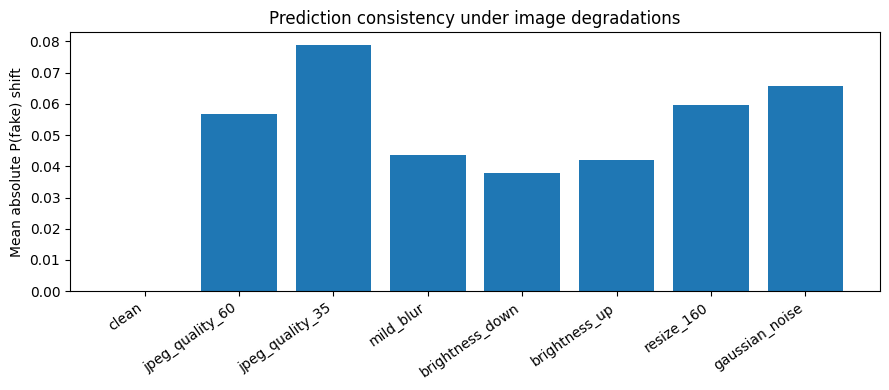

In [22]:
clean_probs = condition_probs["clean"]
consistency_rows = []
for condition, probs in condition_probs.items():
    consistency_rows.append({
        "condition": condition,
        "mean_absolute_probability_shift": float(np.mean(np.abs(probs - clean_probs))),
        "prediction_flip_rate": float(np.mean((probs >= 0.5) != (clean_probs >= 0.5)))
    })
consistency_df = pd.DataFrame(consistency_rows)
display(consistency_df)
consistency_df.to_csv(OUTPUT_DIR / "consistency_results.csv", index=False)

plt.figure(figsize=(9, 4))
plt.bar(consistency_df["condition"], consistency_df["mean_absolute_probability_shift"])
plt.xticks(rotation=35, ha="right")
plt.ylabel("Mean absolute P(fake) shift")
plt.title("Prediction consistency under image degradations")
plt.tight_layout()
plt.show()

## 18. Confidence calibration using temperature scaling

A probability of 0.90 should ideally correspond to roughly 90% positive outcomes among predictions made with similar confidence. Neural networks can be overconfident.

We fit one scalar temperature on validation logits by minimizing validation negative log-likelihood. This does not change the ranking of predictions, but can improve probability calibration. The fitted temperature must be saved and reused in inference.

In [23]:
@torch.no_grad()
def collect_logits(model, loader, dual_stream=True):
    model.eval()
    logits_all, labels_all = [], []
    for rgb, fft, labels in loader:
        rgb = rgb.to(DEVICE)
        fft = fft.to(DEVICE)
        logits = model(rgb, fft) if dual_stream else model(rgb)
        logits_all.append(logits.cpu())
        labels_all.append(labels)
    return torch.cat(logits_all), torch.cat(labels_all)

val_logits, val_targets = collect_logits(fusion_model, val_loader, dual_stream=True)

temperature = nn.Parameter(torch.ones(1))
calibration_optimizer = torch.optim.LBFGS([temperature], lr=0.01, max_iter=100)
criterion = nn.CrossEntropyLoss()

def calibration_closure():
    calibration_optimizer.zero_grad()
    loss = criterion(val_logits / temperature.clamp(min=0.05), val_targets)
    loss.backward()
    return loss

calibration_optimizer.step(calibration_closure)
temperature_value = float(temperature.detach().clamp(min=0.05).item())
print("Learned temperature:", temperature_value)

calibrated_probs = torch.softmax(val_logits / temperature_value, dim=1)[:, 1].numpy()
print("Uncalibrated:", compute_metrics(y_val, p_fusion))
print("Calibrated:", compute_metrics(y_val, calibrated_probs))

with open(OUTPUT_DIR / "calibration.json", "w") as f:
    json.dump({"temperature": temperature_value}, f, indent=2)

Learned temperature: 1.4576395750045776
Uncalibrated: {'accuracy': 0.8121428571428572, 'precision_fake': 0.8387096774193549, 'recall_fake': 0.7755681818181818, 'f1_fake': 0.8059040590405904, 'roc_auc': np.float64(0.8753193981844305)}
Calibrated: {'accuracy': 0.8121428571428572, 'precision_fake': 0.8387096774193549, 'recall_fake': 0.7755681818181818, 'f1_fake': 0.8059040590405904, 'roc_auc': np.float64(0.8753183777429465)}


## 19. Explainability — RGB Grad-CAM

Grad-CAM highlights spatial regions that influence the selected class score. It is an interpretability aid, not proof that the model is correct or that it has learned genuine deepfake artifacts.

We visualize the RGB stream's last convolutional feature maps. For a dual-stream model, the explanation is specifically for the RGB branch; the FFT branch should be inspected separately through its frequency input maps and ablation results.

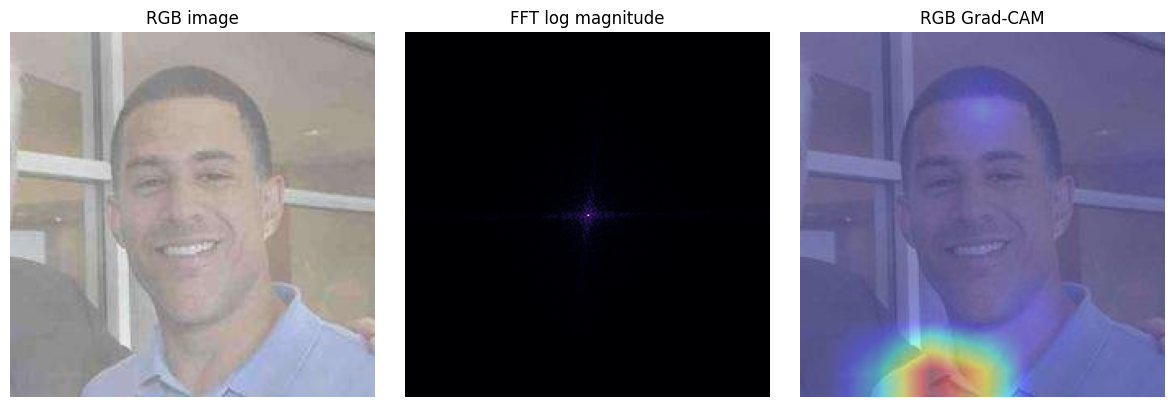

In [24]:
class RGBGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.h1 = target_layer.register_forward_hook(self._save_activation)
        self.h2 = target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inputs, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, rgb, fft, class_index=1):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)
        logits = self.model(rgb, fft)
        score = logits[:, class_index].sum()
        score.backward(retain_graph=True)

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)
        cam = F.interpolate(cam, size=rgb.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy()

    def close(self):
        self.h1.remove()
        self.h2.remove()

target_layer = fusion_model.rgb_features[-1]
gradcam = RGBGradCAM(fusion_model, target_layer)

sample_rgb, sample_fft, sample_label = val_dataset[0]
rgb_input = sample_rgb.unsqueeze(0).to(DEVICE)
fft_input = sample_fft.unsqueeze(0).to(DEVICE)
cam = gradcam.generate(rgb_input, fft_input, class_index=1)
gradcam.close()

rgb_display = sample_rgb.permute(1, 2, 0).cpu().numpy()
rgb_display = np.clip(rgb_display * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN), 0, 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(rgb_display); plt.title("RGB image"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(sample_fft[0], cmap="magma"); plt.title("FFT log magnitude"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(rgb_display); plt.imshow(cam, cmap="jet", alpha=0.4); plt.title("RGB Grad-CAM"); plt.axis("off")
plt.tight_layout()
plt.show()

## 20. Efficiency benchmark

Measure parameter count, checkpoint size, average inference latency and throughput on the current runtime. Timing depends on GPU/CPU, batch size and environment, so report the hardware alongside the numbers.

In [25]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def benchmark_model(model, dual_stream=True, batch_size=1, warmup=10, iterations=50):
    model.eval()
    rgb = torch.randn(batch_size, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)
    fft = torch.randn(batch_size, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)

    with torch.no_grad():
        for _ in range(warmup):
            _ = model(rgb, fft) if dual_stream else model(rgb)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(iterations):
            _ = model(rgb, fft) if dual_stream else model(rgb)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

    latency_ms = (elapsed / iterations) * 1000
    images_per_second = (batch_size * iterations) / elapsed
    return {"batch_size": batch_size, "latency_ms_per_batch": latency_ms,
            "images_per_second": images_per_second}

efficiency = {
    "rgb_trainable_parameters": count_parameters(rgb_model),
    "fusion_trainable_parameters": count_parameters(fusion_model),
    "rgb_checkpoint_mb": rgb_checkpoint.stat().st_size / (1024 ** 2),
    "fusion_checkpoint_mb": fusion_checkpoint.stat().st_size / (1024 ** 2),
    "device": str(DEVICE),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
efficiency["rgb_batch1"] = benchmark_model(rgb_model, dual_stream=False, batch_size=1)
efficiency["fusion_batch1"] = benchmark_model(fusion_model, dual_stream=True, batch_size=1)
efficiency["fusion_batch32"] = benchmark_model(fusion_model, dual_stream=True, batch_size=min(32, BATCH_SIZE))

print(json.dumps(efficiency, indent=2))
with open(OUTPUT_DIR / "efficiency_report.json", "w") as f:
    json.dump(efficiency, f, indent=2)

{
  "rgb_trainable_parameters": 4010110,
  "fusion_trainable_parameters": 4708702,
  "rgb_checkpoint_mb": 15.58813190460205,
  "fusion_checkpoint_mb": 18.27296733856201,
  "device": "cuda",
  "gpu_name": "Tesla T4",
  "rgb_batch1": {
    "batch_size": 1,
    "latency_ms_per_batch": 8.092935959994065,
    "images_per_second": 123.56455122631829
  },
  "fusion_batch1": {
    "batch_size": 1,
    "latency_ms_per_batch": 8.837017040004866,
    "images_per_second": 113.16035665349915
  },
  "fusion_batch32": {
    "batch_size": 32,
    "latency_ms_per_batch": 47.06550636000429,
    "images_per_second": 679.903446809471
  }
}


## 21. Select the final model based on evidence

Do not automatically choose RGB+FFT. Review the validation comparison, robustness table, consistency metrics and efficiency report.

A reasonable selection rule is:
1. Prefer a meaningful validation ROC-AUC/F1 improvement.
2. Check that the improvement is not accompanied by severe robustness degradation.
3. Check inference speed and checkpoint size against the efficiency criteria.
4. If the dual-stream gain is negligible, use the simpler RGB model.

Set `FINAL_MODEL_TYPE` only after reviewing results.

In [26]:
# Choose only after reviewing validation and robustness results:
FINAL_MODEL_TYPE = "fusion"  # "fusion" or "rgb"

if FINAL_MODEL_TYPE == "fusion":
    final_model = fusion_model
    final_checkpoint = fusion_checkpoint
    FINAL_DUAL_STREAM = True
else:
    final_model = rgb_model
    final_checkpoint = rgb_checkpoint
    FINAL_DUAL_STREAM = False

print("Selected:", FINAL_MODEL_TYPE, "| checkpoint:", final_checkpoint)

Selected: fusion | checkpoint: /kaggle/working/deepfake_outputs/rgb_fft_fusion_best.pth


## 22. Generate predictions for all official test images

The confidence column is defined by the organizers as **P(FAKE)**. The label encoding below is provisional:
- `1` = FAKE
- `0` = REAL

Before submission, compare this with the exact `inferencetemplate.py` and organizer documentation. If the template expects strings (`REAL`/`FAKE`) or a different mapping, change the output mapping accordingly.

The `imageid` value below defaults to the filename. Confirm whether the official template expects the full filename, stem, or a separate ID column.

In [27]:
@torch.no_grad()
def predict_test(model, loader, dual_stream=True, temperature=1.0):
    model.eval()
    records = []
    for rgb, fft, paths in tqdm(loader, desc="Predicting test images"):
        rgb = rgb.to(DEVICE, non_blocking=True)
        fft = fft.to(DEVICE, non_blocking=True)
        logits = model(rgb, fft) if dual_stream else model(rgb)
        probabilities = torch.softmax(logits / temperature, dim=1)[:, 1]
        for path, probability in zip(paths, probabilities.cpu().numpy()):
            records.append({
                "image_id": Path(path).stem,
                "label": int(probability >= 0.5),
                "confidence": float(probability)
            })
    return pd.DataFrame(records, columns=["image_id", "label", "confidence"])

predictions = predict_test(
    final_model, test_loader,
    dual_stream=FINAL_DUAL_STREAM,
    temperature=temperature_value if FINAL_DUAL_STREAM else 1.0
)

print("Prediction rows:", len(predictions))
display(predictions.head())
print(predictions["label"].value_counts(dropna=False))

if len(predictions) != len(test_files):
    raise AssertionError(f"Expected {len(test_files)} rows, got {len(predictions)}.")

assert list(predictions.columns) == ["image_id", "label", "confidence"]
assert predictions["image_id"].is_unique, "Duplicate image IDs found."
assert predictions["confidence"].between(0, 1).all(), "Confidence outside [0, 1]."
assert set(predictions["label"].unique()).issubset({0, 1})

predictions_path = OUTPUT_DIR / "predictions.csv"
predictions.to_csv(predictions_path, index=False)
print("Saved:", predictions_path)


Predicting test images:   0%|          | 0/94 [00:00<?, ?it/s]

Prediction rows: 3000


,image_id,label,confidence
0,0020cba7-1d58-4784-91f9-6fc47d9f2806,1,0.908292
1,003fae32-30d9-441b-8fcf-073fc04bf1d1,0,0.069528
2,0061307d-aad7-4d74-a501-ba708c8b1ac8,1,0.990836
3,006aa5af-5db6-413b-a60f-fcc6071ddc3c,1,0.904991
4,009a6a38-29a4-46d4-8ecc-905d776d924e,1,0.986714


label
0    1612
1    1388
Name: count, dtype: int64
Saved: /kaggle/working/deepfake_outputs/predictions.csv


## 23. Save model checkpoint and inference metadata

Save the selected model weights and metadata needed to reproduce preprocessing and calibration. The final inference script must use the same architecture, image size, normalization, label mapping and temperature.

In [28]:
FINAL_WEIGHTS_PATH = OUTPUT_DIR / "model.pth"
torch.save(final_model.state_dict(), FINAL_WEIGHTS_PATH)

metadata = {
    "model_type": FINAL_MODEL_TYPE,
    "image_size": IMAGE_SIZE,
    "class_to_label": CLASS_TO_LABEL,
    "internal_label_mapping": {"real": 0, "fake": 1},
    "confidence_definition": "P(FAKE)",
    "temperature": temperature_value if FINAL_DUAL_STREAM else 1.0,
    "dual_stream": FINAL_DUAL_STREAM,
    "seed": SEED,
    "validation_size": VAL_SIZE,
    "architecture": "EfficientNet-B0 RGB + FFT fusion" if FINAL_DUAL_STREAM else "EfficientNet-B0 RGB",
}
with open(OUTPUT_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved weights:", FINAL_WEIGHTS_PATH)
print(json.dumps(metadata, indent=2))

Saved weights: /kaggle/working/deepfake_outputs/model.pth
{
  "model_type": "fusion",
  "image_size": 224,
  "class_to_label": {
    "real": 0,
    "fake": 1
  },
  "internal_label_mapping": {
    "real": 0,
    "fake": 1
  },
  "confidence_definition": "P(FAKE)",
  "temperature": 1.4576395750045776,
  "dual_stream": true,
  "seed": 42,
  "validation_size": 0.2,
  "architecture": "EfficientNet-B0 RGB + FFT fusion"
}


## 24. Reproducibility check — reload weights and regenerate CSV

This checks that saved weights can be loaded into a fresh model instance and that predictions can be regenerated. The CSV should match the predictions generated above, apart from tiny floating-point differences if the runtime is nondeterministic.

**Competition requirement:** the final `inferencescript.py` must match the supplied `inferencetemplate.py` interface exactly. This notebook cannot safely invent that interface because the template has not yet been inspected.

In [32]:
if FINAL_MODEL_TYPE == "fusion":
    reloaded_model = RGBFrequencyFusion(pretrained=False).to(DEVICE)
else:
    reloaded_model = build_rgb_model(pretrained=False).to(DEVICE)

reloaded_model.load_state_dict(torch.load(FINAL_WEIGHTS_PATH, map_location=DEVICE))
reloaded_model.eval()

reloaded_predictions = predict_test(
    reloaded_model, test_loader,
    dual_stream=FINAL_DUAL_STREAM,
    temperature=temperature_value if FINAL_DUAL_STREAM else 1.0
)

same_ids = predictions["image_id"].equals(reloaded_predictions["image_id"])
max_probability_difference = float(
    np.max(np.abs(predictions["confidence"].to_numpy() -
                  reloaded_predictions["confidence"].to_numpy()))
)
print("Image IDs match:", same_ids)
print("Maximum probability difference:", max_probability_difference)

Predicting test images:   0%|          | 0/94 [00:00<?, ?it/s]

Image IDs match: True
Maximum probability difference: 0.0
